هدف این پروژه، ساخت یک مدل برای پیش‌بینی تغییر قیمت بیت‌کوین در روز بعد است. برای این کار، از قیمت‌ها و حجم معاملات روزهای گذشته استفاده می‌کنیم تا مشخص شود قیمت پایانی روز بعد بیشتر از امروز خواهد بود یا نه.
مسئله دو حالت دارد. اگر قیمت پایانی روز بعد بیشتر از امروز باشد، نتیجه را صعودی در نظر می‌گیریم. اگر قیمت پایانی برابر یا کمتر از امروز باشد، نتیجه نزولی خواهد بود.
برای بررسی عملکرد مدل، نتایج آن را با یک روش ساده مقایسه می‌کنیم که همیشه حالت پرتکرارتر را پیش‌بینی می‌کند. همچنین فقط به درصد پیش‌بینی‌های درست اکتفا نمی‌کنیم و بررسی می‌کنیم که مدل هر دو حالت را چقدر خوب تشخیص می‌دهد. در نهایت، مدل را روی روزهای پایانی داده‌ها آزمایش می‌کنیم تا مشخص شود روی اطلاعات جدید چه عملکردی دارد.

در این مرحله، داده‌های موجود را بررسی می‌کنیم تا با ساختار و وضعیت آن‌ها آشنا شویم. ابتدا مشخص می‌کنیم داده‌ها چه تعداد ردیف و ستون دارند و چه بازه‌ای از زمان را پوشش می‌دهند. سپس وضعیت داده‌ها را از نظر مقادیر خالی، ردیف‌های تکراری، تاریخ‌های جاافتاده و مقادیر غیرعادی بررسی می‌کنیم. در ادامه، نحوه توزیع بازده روزانه و تعداد روزهای صعودی و نزولی را بررسی می‌کنیم تا مشخص شود تغییرات قیمت چه الگویی دارند. در پایان نیز رابطه بین روزهای متوالی را بررسی می‌کنیم تا ببینیم آیا الگوی مشخصی در تغییرات قیمت دیده می‌شود. در این مرحله هیچ تغییری در داده‌ها ایجاد نمی‌کنیم و فقط مشکلات و نکات مهم را برای مراحل بعد ثبت می‌کنیم.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv("btc_daily.csv")
df.columns = df.columns.str.lower()
df["time"] = pd.to_datetime(df["time"])
df.head()

,time,open,high,low,close,volume
0,2025-07-28 01:30:00+03:30,119265.75,119766.65,119228.56,119495.17,773.18425
1,2025-07-28 02:30:00+03:30,119495.16,119528.47,119119.53,119415.55,375.89279
2,2025-07-28 03:30:00+03:30,119415.56,119690.32,119126.09,119236.72,466.02933
3,2025-07-28 04:30:00+03:30,119236.72,119480.00,118960.50,119037.77,475.77219
4,2025-07-28 05:30:00+03:30,119037.77,119800.00,119021.11,119434.14,578.13763


In [21]:
print(df.shape)
print(df.columns.tolist())
df.info()

(10866, 6)
['time', 'open', 'high', 'low', 'close', 'volume']
<class 'pandas.DataFrame'>
RangeIndex: 10866 entries, 0 to 10865
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype                    
---  ------  --------------  -----                    
 0   time    10866 non-null  datetime64[us, UTC+03:30]
 1   open    10866 non-null  float64                  
 2   high    10866 non-null  float64                  
 3   low     10866 non-null  float64                  
 4   close   10866 non-null  float64                  
 5   volume  10866 non-null  float64                  
dtypes: datetime64[us, UTC+03:30](1), float64(5)
memory usage: 509.5 KB


In [4]:
print(df["time"].min())
print(df["time"].max())
print(len(df))
df.describe()

2025-07-28 01:30:00+03:30
2026-10-23 18:30:00+03:30
10866


,open,high,low,close,volume
count,10866.000000,10866.000000,10866.000000,10866.000000,10866.000000
mean,85005.106755,85247.459187,84748.208938,85001.627092,758.183302
std,18273.245512,18298.173208,18239.815146,18270.322752,797.872789
min,58291.700000,58618.650000,57800.190000,58290.170000,46.433460
25%,68839.180000,69098.830000,68545.192500,68839.182500,336.464213
50%,80970.825000,81194.880000,80782.100000,80970.835000,537.514885
75%,95545.987500,95771.630000,95291.195000,95529.227500,892.276745
max,126011.180000,126199.630000,125252.740000,126011.180000,22932.630340


در این بخش، وضعیت کلی داده‌ها را بررسی می‌کنیم تا مشکلات احتمالی مشخص شوند. ابتدا تعداد مقادیر خالی و سطرهای تکراری را بررسی می‌کنیم و بعد سراغ تاریخ‌ها می‌رویم تا مطمئن شویم مرتب هستند و روزی از قلم نیفتاده است. از آنجا که معاملات بیت‌کوین در تمام روزهای هفته انجام می‌شود، انتظار داریم فاصله تاریخ‌های متوالی معمولاً یک روز باشد. در آخر، مقادیر غیرعادی را هم بررسی می‌کنیم؛ برای مثال، بالاترین قیمت روز نباید کمتر از پایین‌ترین قیمت همان روز باشد. نتیجه این بررسی‌ها مشخص می‌کند که در مرحله آماده‌سازی داده‌ها به چه اصلاحاتی نیاز داریم.

In [20]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["time"].duplicated().sum())

time      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64
0
0


In [6]:
print(df["time"].diff().value_counts().head())

time
0 days 01:00:00    10865
Name: count, dtype: int64


In [7]:
print((df["high"] < df["low"]).sum())
print(((df["close"] > df["high"]) | (df["close"] < df["low"])).sum())
print((df["volume"] == 0).sum())
print((df[["open", "high", "low", "close"]] <= 0).sum())

0
0
0
open     0
high     0
low      0
close    0
dtype: int64


در این بخش، نمودار قیمت و حجم معاملات را بررسی می‌کنیم تا دید بهتری از تغییرات آن‌ها در طول زمان داشته باشیم. قیمت بیت‌کوین در این بازه از چند صد دلار به ده‌ها هزار دلار رسیده است و تغییرات زیادی داشته؛ بنابراین، استفاده از قیمت خام به‌تنهایی برای بررسی الگوها کافی نیست. در مرحله بعد، تغییرات درصدی قیمت و شاخص‌های مختلف را بررسی می‌کنیم تا بتوانیم تغییرات بازار را بهتر مقایسه کنیم.
در نمودار دوم، از مقیاس لگاریتمی استفاده شده است. این کار باعث می‌شود رشد قیمت در سال‌های ابتدایی هم بهتر دیده شود و تغییرات آن دوره در مقایسه با قیمت‌های بالاتر سال‌های اخیر کمتر به چشم نیاید.

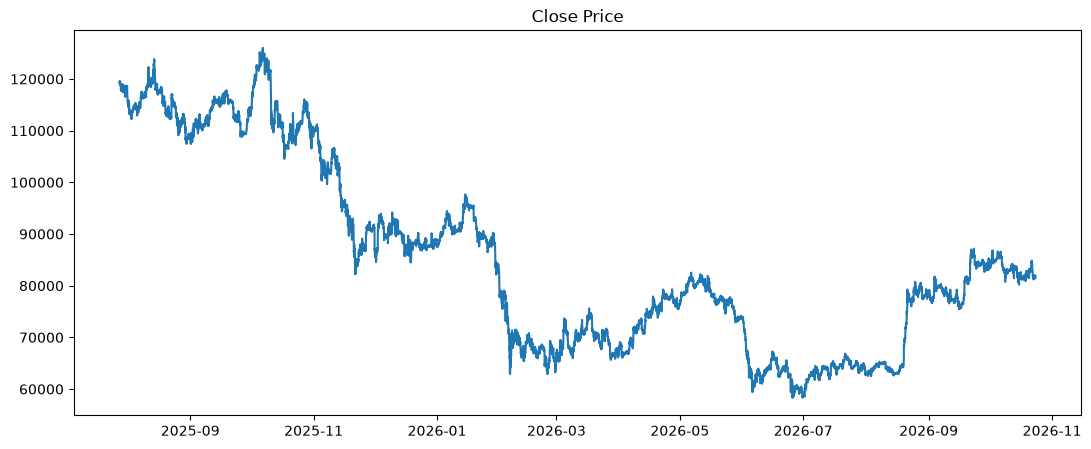

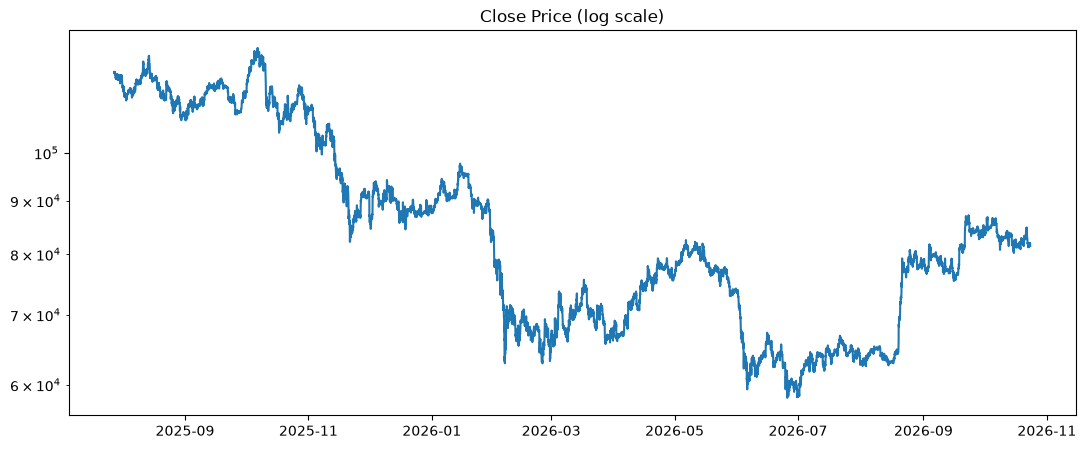

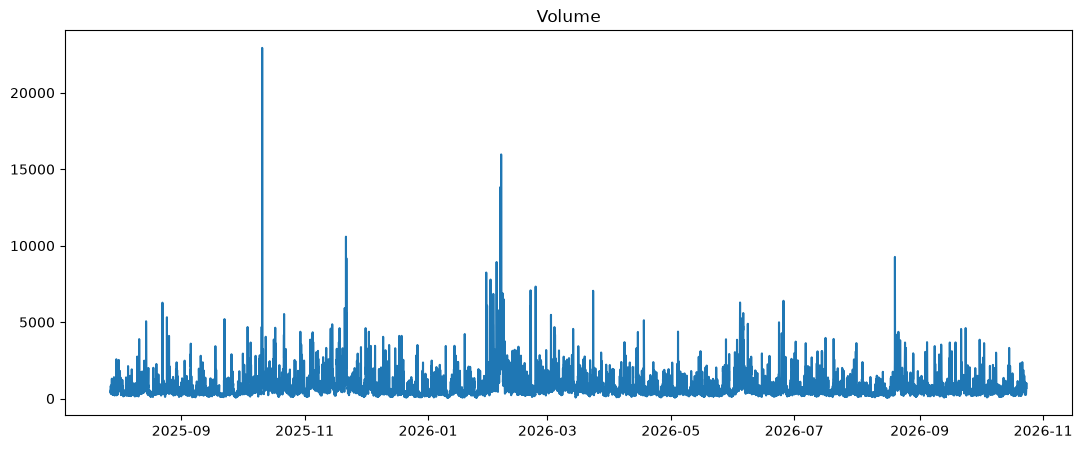

In [22]:
plt.figure(figsize=(13, 5))
plt.plot(df["time"], df["close"])
plt.title("Close Price")
plt.show()

plt.figure(figsize=(13, 5))
plt.plot(df["time"], df["close"])
plt.yscale("log")
plt.title("Close Price (log scale)")
plt.show()

plt.figure(figsize=(13, 5))
plt.plot(df["time"], df["volume"])
plt.title("Volume")
plt.show()

در این بخش، بازده روزانه را محاسبه می‌کنیم تا مشخص شود قیمت بیت‌کوین در هر روز نسبت به روز قبل چند درصد تغییر کرده است.

In [23]:
returns = df["close"].pct_change().dropna()
print(returns.describe())


count    1.086500e+04
mean    -2.537390e-05
std      4.445974e-03
min     -4.823068e-02
25%     -1.887137e-03
50%     -6.795373e-07
75%      1.856534e-03
max      3.990689e-02
Name: close, dtype: float64


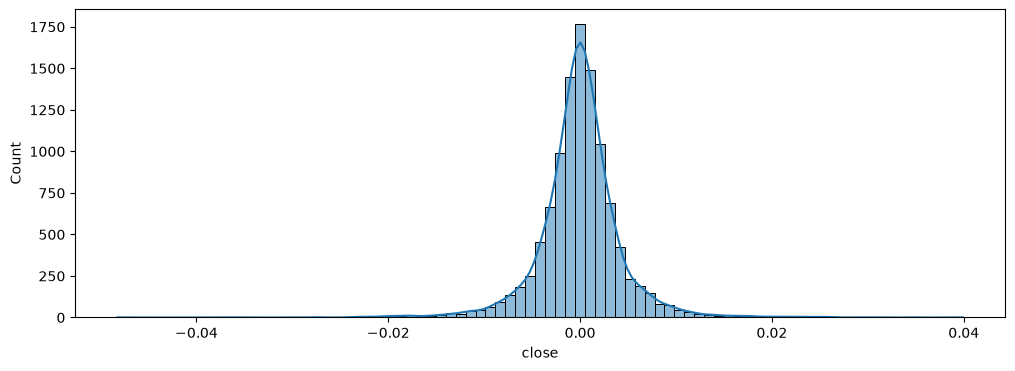

In [24]:
plt.figure(figsize=(12, 4))
sns.histplot(returns, bins=85, kde=True)
plt.show()

در این بخش، بررسی می‌کنیم که آیا قیمت پایانی بیت‌کوین در روز بعد بیشتر از قیمت پایانی امروز خواهد بود یا نه. برای این کار، به‌صورت موقت روزها را به دو دسته صعودی و نزولی تقسیم می‌کنیم تا تعداد و درصد هر دسته مشخص شود. چون برای آخرین روز داده‌ها قیمت روز بعد را نداریم، آن روز را از این بررسی کنار می‌گذاریم.
این بررسی به ما کمک می‌کند تعادل بین دو دسته را بسنجیم و یک معیار ساده برای مقایسه مدل‌ها داشته باشیم. برای مثال، اگر پنجاه‌ودو درصد روزها صعودی باشند، پیش‌بینی همیشگی حالت صعودی به دقت پنجاه‌ودو درصد می‌رسد. بنابراین، برای اینکه مدل عملکرد قابل قبولی داشته باشد، باید نتیجه آن را با این معیار مقایسه کنیم.
در پایان، درصد روزهای صعودی و نزولی و دقت روش ساده مشخص می‌شود.

In [11]:
next_up = (df["close"].shift(-1) > df["close"]).iloc[:-1].astype(int)
print(next_up.value_counts())
print(next_up.value_counts(normalize=True))

close
0    5440
1    5425
Name: count, dtype: int64
close
0    0.50069
1    0.49931
Name: proportion, dtype: float64


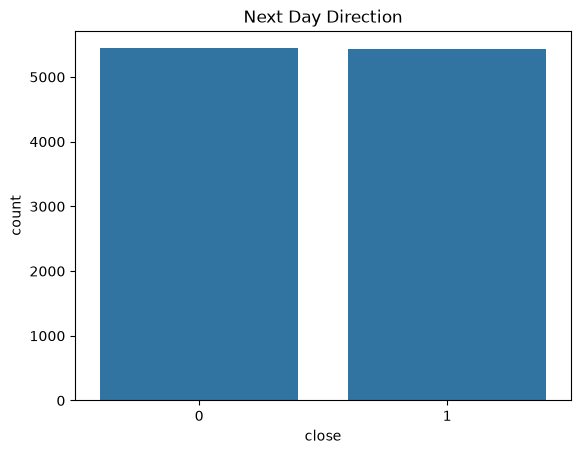

In [12]:
sns.countplot(x=next_up)
plt.title("Next Day Direction")
plt.show()

در این بخش، رابطه بین ستون‌های قیمتی و تغییرات قیمت در روزهای متوالی را بررسی می‌کنیم. ابتدا همبستگی بین قیمت شروع، بالاترین قیمت، پایین‌ترین قیمت و قیمت پایانی را می‌سنجیم.پ
بعد، رابطه بین بازده امروز و روز قبل را بررسی می‌کنیم تا ببینیم آیا تغییرات گذشته می‌توانند اطلاعاتی درباره تغییرات روز بعد داشته باشند یا نه.

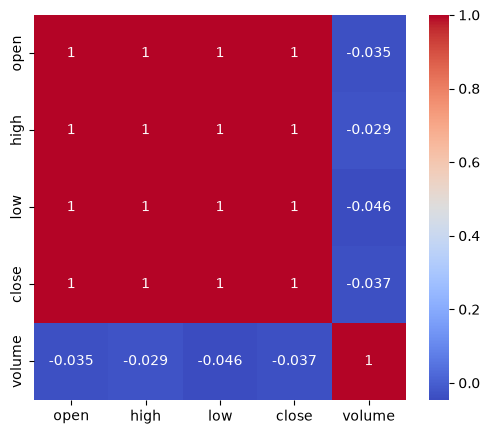

In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.drop(columns="time").corr(), annot=True, cmap="coolwarm")
plt.show()

In [15]:
print(returns.autocorr(lag=1))
print(returns.abs().corr(df["volume"]))

-0.0006929556088211806
0.6014214384301287
